# Rain and cake sales (hypothesis 3)

**Purpose.** Explore hypothesis 3 from the canvas: *on rainy days, the branch sells less cake (product group 5).* This is an exploration, not a model.

> **Summary**
> - **Rain has no significant effect on cake sales**, even with a very specific definition of rain (`Wettercode` 60–69 only). Mean cake turnover is €266 on rainy vs €271 on non-rainy days (Cohen's d = −0.07, p = 0.21). No weekday is significant after correcting for alpha inflation.
> - **Cloud cover is a sensible stand-in for rain:** the share of rainy days rises from 0 % at clear sky to 59 % at cloud cover 7, and rainy days are clearly cloudier (d = 0.94).
> - **But the cloud effect on cake sales is small:** cake turnover drops from about €284 on clear days to €250 at full overcast. The ANOVA is significant (p < 0.0001), yet cloud cover explains only about 3 % of the variation (eta² = 0.031).

- **Part 1 – Rainy days from the weather code:** compare cake sales on rainy and non-rainy days.
- **Part 2 – Cloud cover as a stand-in:** `Wettercode` is not used in training (DECISIONS 2026-11-23); check whether cloud cover (`Bewoelkung`) tracks rain well enough to replace it.

**Definition of "rain" (DECISIONS 2026-11-23).** For data exploration only, a rainy day is `Wettercode` **60–69** (rain at the time of observation), a narrow, conservative definition. WMO codes for reference: 00–19 no precipitation (clouds, haze, mist), 20–29 precipitation in the past hour, 40–49 fog, 50–59 drizzle, **60–69 rain**, 70–79 snow, 80–99 showers and thunderstorms. Missing codes most likely mean "nothing notable reported", but that is not certain, so they stay a separate group.

## Data preparation

1. Load sales and weather; keep weather for the sales period.
2. Label each day **rain** (60–69), **no rain** (other code) or **code missing**.
3. Join cake (group 5) to the weather on `Datum` (left join, sales as the base, DECISIONS 2026-11-23). Sales days without a weather row go to *code missing*.
4. Leave out 31 December: New Year's Eve, not weather, drives those cake peaks.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

BASE_URL = "https://raw.githubusercontent.com/opencampus-sh/intro-to-data-science-and-ml/main/data/bakery/"
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
GROUPS = ["no rain", "rain", "code missing"]

# 1. Load data, keep the sales period
sales = pd.read_csv(BASE_URL + "umsatzdaten_gekuerzt.csv", parse_dates=["Datum"])
weather = pd.read_csv(BASE_URL + "wetter.csv", parse_dates=["Datum"])
weather = weather[weather["Datum"].between("2013-07-01", "2018-07-31")].copy()

# 2. Label rainy days (narrow definition: 60-69)
weather["rain_group"] = weather["Wettercode"].map(
    lambda c: "code missing" if pd.isna(c) else ("rain" if 60 <= c <= 69 else "no rain"))

# 3. Cake sales joined with weather (left join on the sales file)
cake = sales[sales["Warengruppe"] == 5].merge(
    weather[["Datum", "Wettercode", "Bewoelkung", "rain_group"]], on="Datum", how="left")
cake["rain_group"] = cake["rain_group"].fillna("code missing")  # sales days without any weather row
cake["weekday"] = pd.Categorical(cake["Datum"].dt.day_name(), categories=WEEKDAYS, ordered=True)
cake["month"] = cake["Datum"].dt.month

# 4. Leave out 31 December
cake = cake[~((cake["month"] == 12) & (cake["Datum"].dt.day == 31))].copy()

print("sales rows:", len(sales), "| weather days in sales period:", len(weather), "| cake days used:", len(cake))

sales rows: 9334 | weather days in sales period: 1854 | cake days used: 1814


---
# Part 1 – Rainy days from the weather code

First the overall comparison, then *within* each weekday and each month, because cake sales depend on weekday and season. The % column: how much lower (negative) or higher the **mean** turnover is on rainy days. All tables and plots in this notebook report means.

Each comparison of *rain* vs *no rain* also gets two statistics:
- **Cohen's d** – size of the difference in **mean** turnover, in standard deviations: (mean rain − mean no rain) / pooled standard deviation. Rough guide: |d| ≈ 0.2 small, 0.5 medium, 0.8 large. Negative = less cake on rainy days.
- **p-value (t-test)** – Welch's t-test (does not assume equal spread in both groups). It answers: *if rain made no difference to mean turnover, how likely would a difference this large be by chance?* p < 0.05 is the usual threshold for "significant".

**Caution:** the tables run 1 + 7 + 12 = 20 tests. At the 5 % level about 1 in 20 tests is "significant" by chance alone, so a single small p-value in the weekday or month table is weak evidence. A stricter threshold that accounts for this (Bonferroni) is 0.05 / 20 = 0.0025.

In [2]:
from scipy import stats

def rain_test(rain, no_rain):
    """Cohen's d (pooled SD) and Welch t-test p-value for rain vs no rain."""
    n1, n2 = len(rain), len(no_rain)
    pooled_sd = (((n1 - 1) * rain.var() + (n2 - 1) * no_rain.var()) / (n1 + n2 - 2)) ** 0.5
    d = (rain.mean() - no_rain.mean()) / pooled_sd
    p = stats.ttest_ind(rain, no_rain, equal_var=False).pvalue
    p_text = "< 0.0001" if p < 0.0001 else f"{p:.4f}"
    return pd.Series({"Cohen's d": round(d, 2), "p-value (t-test)": p_text})

summary = cake.groupby("rain_group")["Umsatz"].agg(days="count", mean_turnover="mean",
                                                   sd_turnover="std").loc[GROUPS]
summary["weather days in period"] = weather["rain_group"].value_counts()[GROUPS]
display(summary.round(1))

print("Rain vs no rain, all days:")
rain_test(cake.loc[cake["rain_group"] == "rain", "Umsatz"],
          cake.loc[cake["rain_group"] == "no rain", "Umsatz"]).to_frame("value")

,days,mean_turnover,sd_turnover,weather days in period
rain_group,,,,
no rain,789,270.6,65.4,808
rain,567,266.0,67.5,583
code missing,458,285.3,59.3,463


Rain vs no rain, all days:


,value
Cohen's d,-0.07
p-value (t-test),0.2077


In [3]:
def compare(by):
    t = cake.pivot_table(index=by, columns="rain_group", values="Umsatz",
                         aggfunc="mean", observed=False)[["no rain", "rain"]]
    t["rain vs no rain (%)"] = (t["rain"] / t["no rain"] - 1) * 100
    t["rainy days"] = cake[cake["rain_group"] == "rain"].groupby(by, observed=False).size()
    tests = cake.groupby(by, observed=False).apply(
        lambda g: rain_test(g.loc[g["rain_group"] == "rain", "Umsatz"],
                            g.loc[g["rain_group"] == "no rain", "Umsatz"]))
    return t.round(1).join(tests)

print("Mean cake turnover (€) per weekday, with effect size and t-test:")
display(compare("weekday"))
print("Mean cake turnover (€) per month, with effect size and t-test:")
display(compare("month"))

Mean cake turnover (€) per weekday, with effect size and t-test:


C:\Users\tping\AppData\Local\Temp\ipykernel_22336\444217593.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tests = cake.groupby(by, observed=False).apply(


,no rain,rain,rain vs no rain (%),rainy days,Cohen's d,p-value (t-test)
weekday,,,,,,
Monday,252.7,247.4,-2.1,78,-0.08,0.5940
Tuesday,254.4,242.3,-4.8,79,-0.24,0.0942
Wednesday,253.9,248.4,-2.2,83,-0.10,0.4786
Thursday,255.8,257.0,0.5,75,0.02,0.8861
Friday,265.4,259.5,-2.2,87,-0.10,0.4737
Saturday,305.6,301.8,-1.2,89,-0.05,0.7444
Sunday,306.4,303.2,-1.1,76,-0.05,0.7515


Mean cake turnover (€) per month, with effect size and t-test:


C:\Users\tping\AppData\Local\Temp\ipykernel_22336\444217593.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tests = cake.groupby(by, observed=False).apply(


,no rain,rain,rain vs no rain (%),rainy days,Cohen's d,p-value (t-test)
month,,,,,,
1,248.7,235.4,-5.4,58,-0.28,0.0943
2,284.7,264.1,-7.2,44,-0.35,0.0653
3,254.7,239.0,-6.2,38,-0.30,0.1169
4,254.7,254.2,-0.2,47,-0.01,0.9619
5,271.6,274.8,1.2,33,0.05,0.7851
6,290.0,305.3,5.3,40,0.23,0.3094
7,299.4,302.9,1.2,44,0.07,0.7096
8,344.7,362.8,5.3,43,0.24,0.2496
9,282.6,298.0,5.4,45,0.29,0.1704


**What to check:** Is cake lower on rainy days on (almost) every weekday and month, or only sometimes? Are the effect sizes small or medium? Which p-values stay below the strict threshold of 0.0025? Does *code missing* behave like *no rain*?

---
# Part 2 – Cloud cover as a stand-in for rain

`Bewoelkung` = mean cloud cover in octas (0 = clear … 8 = overcast). It has almost no gaps, but cloudy is not the same as rainy. Using the rain definition from Part 1, we check:

1. How cloudy are rainy days compared with other days?
2. How often does it rain at each cloud-cover level?
3. Does cake turnover change with cloud cover in the same way as with rain?

## 2.1 Cloud cover on rainy and non-rainy days

Cohen's d and the t-test here compare **cloud cover** (not cake) on rainy vs non-rainy days: a large positive d means rainy days are clearly cloudier.

In [4]:
w = weather[weather["Bewoelkung"].notna()]
display(w.groupby("rain_group")["Bewoelkung"].agg(["count", "mean", "std"]).loc[GROUPS].round(2))

print("Cloud cover, rain vs no rain:")
rain_test(w.loc[w["rain_group"] == "rain", "Bewoelkung"],
          w.loc[w["rain_group"] == "no rain", "Bewoelkung"]).to_frame("value")

,count,mean,std
rain_group,,,
no rain,808,4.44,2.67
rain,583,6.49,1.19
code missing,453,2.91,2.55


Cloud cover, rain vs no rain:


,value
Cohen's d,0.94
p-value (t-test),< 0.0001


## 2.2 Share of rainy days per cloud-cover level

If cloud cover is a good stand-in, the share of rainy days should rise clearly with cloud cover and be close to 0 on clear days.

**Confidence interval.** The error bars show a 95 % **Wilson interval** for the share of rainy days: the range in which the true share plausibly lies, given how many days we have at that level. Levels with few days get wider bars.

rain_group,no rain,rain,code missing,days,rain CI low,rain CI high
Bewoelkung,,,,,,
0.0,48.1,0.0,51.9,241,0.0,1.6
1.0,50.5,2.7,46.8,111,0.9,7.6
2.0,48.5,6.8,44.7,103,3.3,13.4
3.0,52.6,6.0,41.4,116,3.0,11.9
4.0,52.2,17.9,29.9,134,12.3,25.3
5.0,44.1,29.1,26.8,179,22.9,36.1
6.0,45.8,38.1,16.2,260,32.4,44.1
7.0,34.4,58.9,6.7,569,54.8,62.8
8.0,46.6,42.7,10.7,131,34.6,51.3


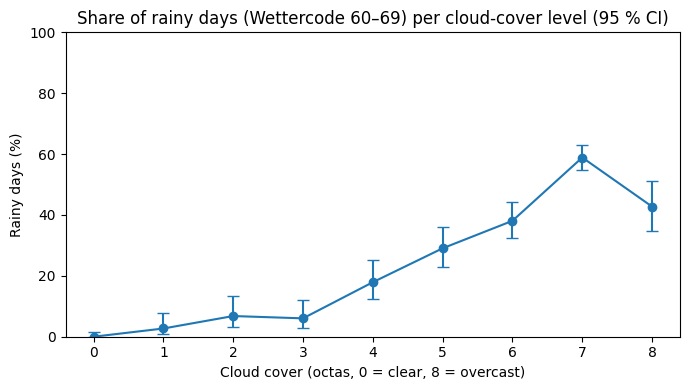

In [5]:
def wilson_ci(k, n, z=1.96):
    """95 % Wilson confidence interval for a share k/n, in %."""
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * ((p * (1 - p) / n + z**2 / (4 * n**2)) ** 0.5) / (1 + z**2 / n)
    return (centre - half) * 100, (centre + half) * 100

share = (w.groupby("Bewoelkung")["rain_group"].value_counts(normalize=True)
          .unstack().fillna(0)[GROUPS] * 100)
share["days"] = w.groupby("Bewoelkung").size()
rainy = w[w["rain_group"] == "rain"].groupby("Bewoelkung").size().reindex(share.index, fill_value=0)
share["rain CI low"], share["rain CI high"] = wilson_ci(rainy, share["days"])
display(share.round(1))

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(share.index, share["rain"],
            yerr=[share["rain"] - share["rain CI low"], share["rain CI high"] - share["rain"]],
            marker="o", capsize=4)
ax.set_xlabel("Cloud cover (octas, 0 = clear, 8 = overcast)")
ax.set_ylabel("Rainy days (%)")
ax.set_title("Share of rainy days (Wettercode 60–69) per cloud-cover level (95 % CI)")
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

## 2.3 Cake turnover per cloud-cover level

If rain lowers cake sales and cloud cover tracks rain, cake turnover should fall towards the overcast end.

**Confidence interval.** The error bars show the 95 % confidence interval of the **mean**: mean ± t × standard error, where the standard error = standard deviation / √(number of days). Levels with few days or much spread get wider bars. If the intervals of two levels do not overlap, the difference between them is unlikely to be chance.

,days,mean,sd,CI low,CI high
Bewoelkung,,,,,
0.0,240,284.3,61.4,276.5,292.1
1.0,109,287.0,54.5,276.7,297.4
2.0,102,274.0,51.3,263.9,284.0
3.0,115,289.3,60.9,278.0,300.5
4.0,131,282.0,67.9,270.3,293.7
5.0,176,282.6,64.5,273.0,292.2
6.0,251,272.4,64.5,264.4,280.4
7.0,551,262.7,67.4,257.1,268.3
8.0,127,250.2,68.6,238.2,262.3


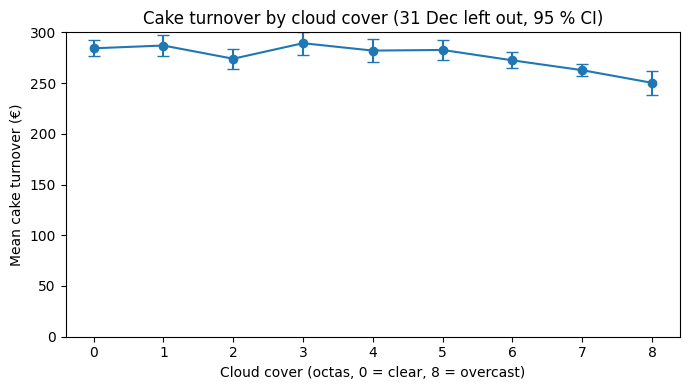

In [6]:
import numpy as np

by_cloud = cake.groupby("Bewoelkung")["Umsatz"].agg(days="count", mean="mean", sd="std")
half_width = stats.t.ppf(0.975, by_cloud["days"] - 1) * by_cloud["sd"] / np.sqrt(by_cloud["days"])
by_cloud["CI low"], by_cloud["CI high"] = by_cloud["mean"] - half_width, by_cloud["mean"] + half_width
display(by_cloud.round(1))

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(by_cloud.index, by_cloud["mean"], yerr=half_width, marker="o", capsize=4)
ax.set_xlabel("Cloud cover (octas, 0 = clear, 8 = overcast)")
ax.set_ylabel("Mean cake turnover (€)")
ax.set_title("Cake turnover by cloud cover (31 Dec left out, 95 % CI)")
ax.set_ylim(0,300)
plt.tight_layout()
plt.show()

## 2.4 ANOVA: does cake turnover differ between cloud-cover levels?

A **one-way ANOVA** (analysis of variance) compares the **mean** cake turnover of all 9 cloud-cover levels at once. It asks: *is the variation between the levels larger than we would expect from the day-to-day variation within each level?*

- **F-statistic** – between-level variation divided by within-level variation. Around 1 = no difference.
- **p-value** – if all levels had the same mean, how likely would an F this large be by chance? p < 0.05 = significant.
- **eta² (η²)** – share of the total variation in cake turnover explained by cloud cover (0–1). Rough guide: 0.01 small, 0.06 medium, 0.14 large.

**Limits.** ANOVA only says *whether* at least one level differs, not *which* (see the confidence intervals in 2.3). It assumes similar spread in every level (compare the `sd` column in 2.3). Cloud cover also varies with the season, so part of any difference may be a season effect.

In [7]:
levels = [g["Umsatz"].to_numpy() for _, g in cake.dropna(subset=["Bewoelkung"]).groupby("Bewoelkung")]
all_values = np.concatenate(levels)

f_stat, p_anova = stats.f_oneway(*levels)
ss_between = sum(len(g) * (g.mean() - all_values.mean()) ** 2 for g in levels)
ss_total = ((all_values - all_values.mean()) ** 2).sum()

pd.DataFrame({
    "F": [round(f_stat, 2)],
    "p-value": ["< 0.0001" if p_anova < 0.0001 else f"{p_anova:.4f}"],
    "eta²": [round(ss_between / ss_total, 3)],
    "groups / days": [f"{len(levels)} / {len(all_values)}"],
}, index=["one-way ANOVA"])

,F,p-value,eta²,groups / days
one-way ANOVA,7.11,< 0.0001,0.031,9 / 1802
